# Fase 5 - Actividad Final: Evaluacion Hold-out (BETO - Google Colab)

Este notebook toma el **modelo BETO ya ajustado** y lo evalúa contra el conjunto de datos `test_blind_set.csv`.
**Instrucciones para Colab:**
1. Sube tu carpeta del proyecto (o al menos los datos `test_blind_set.csv` y la carpeta `beto_final_model`) a Google Drive.
2. Asegúrate de habilitar la GPU (Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU).
3. Ejecuta las celdas.

In [ ]:
!pip install -q transformers torch tqdm scikit-learn pandas matplotlib seaborn joblib

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Cambia esta ruta a donde hayas subido tu proyecto en Drive
import os
RUTA_PROYECTO = '/content/drive/MyDrive/ProyectoFinal_ML'
if os.path.exists(RUTA_PROYECTO):
    os.chdir(RUTA_PROYECTO)
    print(f"Directorio de trabajo cambiado a: {os.getcwd()}")
else:
    print("Asegúrate de cambiar RUTA_PROYECTO a la ruta correcta en tu Google Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Directorio de trabajo cambiado a: /content/drive/MyDrive/ProyectoFinal_ML


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

## 1. Carga del Conjunto de Prueba Ciego (Hold-out)

In [ ]:
TEST_PATH = 'data/test_blind_set.csv'

if not os.path.exists(TEST_PATH):
    print(f"ERROR: No se encuentra {TEST_PATH}. Verifica tu ruta de Google Drive.")
else:
    df_test = pd.read_csv(TEST_PATH, sep=';')
    df_test['texto_beto'] = df_test['texto_beto'].fillna('')

    print(f"Conjunto Ciego (Hold-out) cargado.")
    print(f"   Total de registros : {len(df_test):,}")
    print(f"   Distribucion de clases:\n{df_test['label'].value_counts(normalize=True) * 100}")

    y_true = df_test['label'].values

Conjunto Ciego (Hold-out) cargado.
   Total de registros : 11,447
   Distribucion de clases:
label
1    58.277278
0    41.722722
Name: proportion, dtype: float64


## 2. Helper: Funcion para graficar Matriz de Confusion

In [ ]:
def graficar_matriz(y_real, y_pred, titulo, ax):
    cm = confusion_matrix(y_real, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Falso (0)', 'Real (1)'],
                yticklabels=['Falso (0)', 'Real (1)'])
    ax.set_title(titulo, fontsize=14)
    ax.set_ylabel('Valor Real')
    ax.set_xlabel('Prediccion')

## 3. Evaluacion: Transformer (BETO)

In [ ]:
RUTA_BETO = 'beto_final_model'
resultados_beto = None

if os.path.exists(RUTA_BETO):
    print("Cargando modelo BETO y dependencias de PyTorch...")
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Usando dispositivo: {device}")

    tokenizer = AutoTokenizer.from_pretrained(RUTA_BETO)
    model = AutoModelForSequenceClassification.from_pretrained(RUTA_BETO)
    model.to(device)
    model.eval()

    class TextDataset(Dataset):
        def __init__(self, texts, tokenizer):
            self.texts = texts
            self.tokenizer = tokenizer

        def __len__(self):
            return len(self.texts)

        def __getitem__(self, idx):
            return self.texts[idx]

    test_dataset = TextDataset(df_test['texto_beto'].tolist(), tokenizer)
    test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

    print(f"Evaluando BETO sobre conjunto ciego...")
    y_pred_beto = []

    t_start = time.perf_counter()

    with torch.no_grad():
        for batch_texts in tqdm(test_loader, desc="Inferencia BETO"):
            inputs = tokenizer(
                batch_texts,
                padding='max_length',
                truncation=True,
                max_length=512,
                return_tensors='pt'
            )
            inputs = {k: v.to(device) for k, v in inputs.items()}
            outputs = model(**inputs)
            preds = torch.argmax(outputs.logits, dim=-1).cpu().numpy()
            y_pred_beto.extend(preds)

    t_end = time.perf_counter()

    f1_beto = f1_score(y_true, y_pred_beto, average='macro')
    acc_beto = accuracy_score(y_true, y_pred_beto)

    resultados_beto = {
        'pred': y_pred_beto,
        'f1': f1_beto,
        'acc': acc_beto,
        'time_ms_per_sample': ((t_end - t_start) / len(df_test)) * 1000
    }
    print(f"  [OK] F1-Macro: {f1_beto:.4f} | Accuracy: {acc_beto:.4f}")
else:
    print(f"  [!] Carpeta '{RUTA_BETO}' no encontrada. Revisa la ruta.")

Cargando modelo BETO y dependencias de PyTorch...
Usando dispositivo: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Evaluando BETO sobre conjunto ciego...


Inferencia BETO:   0%|          | 0/716 [00:00<?, ?it/s]

  [OK] F1-Macro: 0.9684 | Accuracy: 0.9692


## 4. Reporte Final

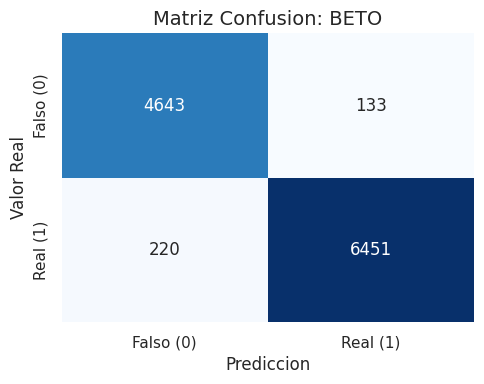

,F1-Score Macro,Accuracy,Tiempo / Noticia (ms)
Modelo,,,
BETO,0.9684,0.9692,32.99



 REPORTE DE CLASIFICACION (HOLD-OUT) - BETO
              precision    recall  f1-score   support

       Falso       0.95      0.97      0.96      4776
        Real       0.98      0.97      0.97      6671

    accuracy                           0.97     11447
   macro avg       0.97      0.97      0.97     11447
weighted avg       0.97      0.97      0.97     11447



In [ ]:
if resultados_beto:
    fig, ax = plt.subplots(1, 1, figsize=(5, 4))

    graficar_matriz(y_true, resultados_beto['pred'], "Matriz Confusion: BETO", ax)

    plt.tight_layout()
    plt.show()

    resumen_lista = [{
        'Modelo': 'BETO',
        'F1-Score Macro': round(resultados_beto['f1'], 4),
        'Accuracy': round(resultados_beto['acc'], 4),
        'Tiempo / Noticia (ms)': round(resultados_beto['time_ms_per_sample'], 2)
    }]

    df_resumen = pd.DataFrame(resumen_lista)
    display(df_resumen.set_index('Modelo'))

    print("\n" + "="*60)
    print(" REPORTE DE CLASIFICACION (HOLD-OUT) - BETO")
    print("="*60)
    print(classification_report(y_true, resultados_beto['pred'], target_names=['Falso', 'Real']))
else:
    print("No se evaluó BETO con éxito.")